In [16]:
from random import randrange
import math
import copy
import matplotlib.pyplot as plt
import numpy
boardRange = 1
use = -1
def GenerateDeck():
    d = []
    for i in range(13):
        for j in range(4):
            d.append([i+1,j%2+1,j+1])
    return d
#rev = [cards]
rev = []
deck52 = GenerateDeck()
nrev = copy.deepcopy(deck52)
def NewCard():
    if (len(deck52)>1):
        c = deck52[randrange(0,len(deck52)-1)]
        deck52.remove(c)
        return c
    else:
        d = deck52[0]
        deck52.remove(d)
        return d
#card = [#, color, suit]
#                           -> [number (t=10, j=11, q=12, k=13), color (1=black, 2=red), suit (1=spade, 2=heart, 3=club, 4=diamond))] 0=unknown / -1=empty
#tab = [[[cards], # of cards beneath (0-6)]]
tab = [[],[],[],[],[],[],[]]
tableau = [[],[],[],[],[],[],[]]
for i in range(7):
    tab[i] = [],i
    for j in range(i):
        tableau[i].append(NewCard())

#deck = [cards]
deck = []

#board [[Spades],[Hearts],[Clubs],[Diamonds]]
board = [[],[],[],[]]

def Reveal(card):
    if (card!=-1):
        if (card[2]==0):
            if (card[1]==1):
                if ([card[0], 1, 1] in rev) and not ([card[0], 1, 3] in rev):
                    card[2] = 3
                if ([card[0], 1, 3] in rev) and not ([card[0], 1, 1] in rev):
                    card[2] = 1
            elif (card[1]==2):
                if ([card[0], 2, 2] in rev) and not ([card[0], 2, 4] in rev):
                    card[2] = 4
                if ([card[0], 2, 4] in rev) and not ([card[0], 2, 2] in rev):
                    card[2] = 2
        if card not in rev and card[2]!=0:
            rev.append(card)
            nrev.remove(card)
    return card
def NewDeck():
    global rev; global deck52; global nrev; global tab; global tableau; global deck; global board
    rev = []
    deck52 = GenerateDeck()
    nrev = copy.deepcopy(deck52)
    tab = [[],[],[],[],[],[],[]]
    tableau = [[],[],[],[],[],[],[]]
    for i in range(7):
        tab[i] = [],i
        for j in range(i):
            tableau[i].append(NewCard())
    deck = []
    board = [[],[],[],[]]

    for i in range(7):
        tab[i] = [[Reveal(NewCard())], tab[i][1]]

    for i in range(8):
        deck.append(0)
        deck.append(0)
        deck.append(0)
        deck[3*i+2] = Reveal(NewCard())
        deck[3*i+1] = NewCard()
        deck[3*i] = NewCard()
def BoardRange(bR):
    global use
    if (use!= -1):
        l = []
        for b in board:
            if (len(b)>0):
                l.append(b[len(b)-1][0])
            else:
                l.append(0)
        if (len(l)>0):
            return min(l)+bR
        else:
            return bR
    else:
        return 100
#returns the complement of a given card
def Complement(card):
    comp = (card[2]+2)%4
    if (comp==0):
        comp=4
    c = [card[0], card[1], comp]
    
    return c
def Card(c):
    if (c==-1):
        return '**'
    else:
        suit = '*'
        if (c[2]==1):
            suit = 's'
        elif (c[2]==2):
            suit = 'h'
        elif (c[2]==3):
            suit = 'c'
        elif (c[2]==4):
            suit = 'd'
        if (c[0]==1):
            return f'A{suit}'
        if (c[0]==10):
            return f'T{suit}'
        if (c[0]==11):
            return f'J{suit}'
        if (c[0]==12):
            return f'Q{suit}'
        if (c[0]==13):
            return f'K{suit}'
        return f'{c[0]}{suit}'
def Deck(d, i):
    d[3*i] = Reveal(d[3*i])
    d[3*i+1] = Reveal(d[3*i+1])
    d[3*i+2] = Reveal(d[3*i+2])
    return f'{Card(d[3*i])} {Card(d[3*i+1])} {Card(d[3*i+2])}'
def Table():
    str = f''
    for j in range(13):
        for i in range(7):
            if (len(tab[i][0])>j):
                str += f'{Stack(tab[i][0],j)} '
            else:
                str += f'   '
        str += f'\n'
    return str
def Tableau():
    str = f''
    for j in range(7):
        str += f'({tab[j][1]})'
    return str + '\n'
def Stack(t,j):
    if (t==[]):
        return '  '
    else:
        return f'{Card(t[j])}'
def Board(i,s):
    if (len(board[i])==0):
        return f'0{s}'
    return Card(board[i][len(board[i])-1])
def GameBoard(j):
    str = f'{Board(0,"s")} {Board(1,"h")} {Board(2,"c")} {Board(3,"d")} {Deck(deck, j)}\n'
    str += Tableau()
    str += Table()
    print(str)
for i in range(7):
    tab[i] = [[Reveal(NewCard())], tab[i][1]]
for i in range(8):
    deck.append(0)
    deck.append(0)
    deck.append(0)
    deck[3*i+2] = Reveal(NewCard())
    deck[3*i+1] = NewCard()
    deck[3*i] = NewCard()
# Deck
#Checks if a card can be moved to the table
def CanMove(card):
    for i in range(7):
        if (tab[i][0]!=[]):
            t = tab[i][0][len(tab[i][0])-1]
            if ((t[0] == card[0] + 1) and (t[1] != card[1])):
                return True, i
        else:
            if (card[0] == 13):
                return True, i
    return False, -1
#0 - Table, 1 - Board
def TableMoves():
    global boardRange
    moves = []
    i=0
    for stack in tab:
        if (len(stack[0])>0):
            c = CanMove(stack[0][0])
            suit = stack[0][len(stack[0])-1][2]-1
            if (len(board[suit])>0):
                if (stack[0][len(stack[0])-1][0]==board[suit][len(board[suit])-1][0]+1) and (stack[0][len(stack[0])-1][0] <= BoardRange(boardRange)):
                    moves.append((-1, (1, i, stack[0][len(stack[0])-1][2]-1), stack[0][0][0], stack[1]))
                elif (c[0] and ((stack[1]!=0) or (stack[0][0][0] !=13))):
                    moves.append((-1, (0, i, c[1]), stack[0][0][0], stack[1]))
            else:
                if (stack[0][len(stack[0])-1][0]==1):
                    moves.append((-1, (1, i, stack[0][len(stack[0])-1][2]-1), stack[0][0][0], stack[1]))
                elif (c[0] and ((stack[1]!=0) or (stack[0][0][0] !=13))):
                    moves.append((-1, (0, i, c[1]), stack[0][0][0], stack[1]))
        i+=1

    #sort move by stacks with most cards
    return moves
#move = (#,#),# ((starting point,position) - end point) 0-6=table, 7=deck
def DeckMoves(i):
    moves = ()
    minideck = 2
    card = deck[3*i + minideck]

    while(minideck >= 0 and card == -1):
        minideck -= 1
        card = deck[3*i + minideck]

    if (minideck >= 0):
        if (len(board[card[2]-1])==0):
            if (card[0]==1): #Check current board num & range of board (keep within ~1)
                moves = (i, (1, i, card[2]-1), card[0])
            elif (CanMove(card)[0]):
                moves = (i, (0, i, CanMove(card)[1]), card[0])
        else:
            if (card[0]==board[card[2]-1][len(board[card[2]-1])-1][0]+1): #Check current board num & range of board (keep within ~1)
                moves = (i, (1, i, card[2]-1), card[0])
            elif (CanMove(card)[0]):
                moves = (i, (0, i, CanMove(card)[1]), card[0])
    return moves

def Score():
    score = 0
    #new card revealed
    #score += stack size

    #tentative score idea - moreso a tiebreaker
    #cards from deck < 3 (EXCEPTION if card moved is from the absolute top of deck)
    #score += bonus

    #card moved to board
    #score += #

    #card moved from deck
    #score += #

    return score
def MidDeckMove(inf):
    #info -> (start, depth, end)
    #take from one deck, move to another, reveal cards
    endDeck = tab[inf[2]][0]+tab[inf[0]][0][inf[1]+1:]
    startDeck = tab[inf[0]][0][:inf[1]+1]
    tab[inf[0]]
    tab[inf[0]] = [startDeck,tab[inf[0]][1]]
    tab[inf[2]] = [endDeck,tab[inf[2]][1]]
#(-2, (start deck, depth, end deck), board card)
def EndGameStrats():
    soughtCards = []
    for i in range(4):
        c = []
        if len(board[i]) > 0:
            c = [board[i][len(board[i])-1][0]+1, board[i][len(board[i])-1][1], board[i][len(board[i])-1][2]]
        soughtCards.append(c)
    
    moves = []
    for i in range(7):
        for j in range(4):
            if soughtCards[j] in tab[i][0]:
                if (len(tab[i][0][tab[i][0].index(soughtCards[j])+1:])>0):
                    for k in range(7):
                        if (len(tab[k][0])>0):
                            if tab[k][0][len(tab[k][0])-1] == Complement(soughtCards[j]):
                                #look for complement card
                                moves.append((-2, (i, tab[i][0].index(soughtCards[j]), k), j))
    return moves
def Moves():
    tmoves = []
    dmoves = []
    for i in range(math.ceil(len(deck)/3)):
        m = DeckMoves(i)
        if (len(m)>0):
            dmoves.append(m)

    if (len(TableMoves())>0):
        tmoves = TableMoves()

        '''Strategy1: Reverse Order
        Orders by stack, so reverse order starts with rightmost stack'''
        #tmoves.reverse()

        '''Strategy 2: Sort By Stack Size
        Starting with biggest stack move'''
        tmoves = sorted(tmoves, key=lambda tup: tup[3])
        tmoves.reverse()
        
    moves = tmoves + dmoves

    '''Strategy 3: Sort By Card Number
    Orders all moves based on lowest card value'''
    #moves = sorted(moves, key=lambda tup: tup[2])
    #moves.reverse()

    '''Strategy 4: Prioritizes A's and 2's
    Pick out the 1 and 2 moves and put at the front'''
    '''ones = []
    twos = []
    for i in range(len(moves)):
        if (moves[i][2]==1):
            ones.append(moves[i])
        elif (moves[i][2]==2):
            twos.append(moves[i])
    for i in range(len(ones)):
        moves.remove(ones[i])
    for i in range(len(twos)):
        moves.remove(twos[i])
    moves = ones + twos + moves'''

    return moves
deckLoc = 0
score = 0
def ShiftDeck():
    global score; score -= 20
    if (len(deck)>0):
        i = 0
        swap = -1
        while (i<len(deck)):
            if (deck[i]==-1):
                if (swap==-1):
                    swap = i
            elif (swap != -1):
                deck[swap] = deck[i]
                deck[i] = -1
                swap = -1
                i=swap
            i+=1
    return
def Execute(m):
    #move = (deck location, (0=table/1=board, #=tableLoc/deckLoc, #=tableLoc/boardLoc))
    global score
    global deckLoc
    if (m[0]==-1):
        #Table Moves
        id = m[1]
        #table to table
        if (id[0]==0):
            #add stack to table
            for c in tab[id[1]][0]:
                tab[id[2]][0].append(c)
            #remove stack from table
            tab[id[1]][0] = []
            if ((tab[id[1]][1])>0):
                tab[id[1]][1] -= 1
                tab[id[1]][0].append(Reveal(tableau[id[1]][tab[id[1]][1]-1]))
                score+=20
        #table to board
        else:
            c = tab[id[1]][0][len(tab[id[1]][0])-1]
            tab[id[1]][0].remove(c)
            if (len(tab[id[1]][0])==0 and (tab[id[1]][1])>0):
                tab[id[1]][1] -= 1
                tab[id[1]][0].append(Reveal(tableau[id[1]][tab[id[1]][1]-1]))
                score+=20
            board[id[2]].append(c)
            score+=100
    else:
        #Table Moves
        id = m[1]
        j = 2
        c = deck[3*m[0]+j]
        while(c==-1):
            j-=1
            c = deck[3*m[0]+j]
        #deck to table
        if (id[0]==0):
            tab[id[2]][0].append(c)
            deck[3*m[0]+j] = -1
            score+=20
        #deck to board
        else:
            board[id[2]].append(c)
            deck[3*m[0]+j] = -1
            score+=100

lastShift = False
def Turn(i):
    global deckLoc
    global lastShift
    global boardRange
    global RandomStrats
    e = EndGameStrats()
    if (len(e)>0 and MidDeckStrats and not(any(item[0]==-1 and item[1][0]==1 for item in Moves()))):
        if (e[0][0]==-2):
            MidDeckMove(e[0][1])
            lastShift = False
        #==-3 for return from board moves
    else:
        if (len(Moves())==0):
            if (BoardRange(0)==13):
                print('You Won!')
                return 2
            elif (deckLoc > 0):
                deckLoc = 0
                ShiftDeck()
                lastShift = False
                boardRange = 1
            elif (lastShift):
                if (boardRange < 13):
                    boardRange += 1
                else:
                    e = EndGameStrats()
                    if (len(e)>0):
                        if (e[0][0]==-2):
                            MidDeckMove(e[0][1])
                            lastShift = False
                        #==-3 for return from board moves
                    else:
                        #print('Game Over...')
                        return 0
            else:
                ShiftDeck()
                lastShift = True
                boardRange = 1
        else:
            lastShift = False
            #Game Logic Here
            if (RandomStrats):
                if (Moves()[i][0]==-1):
                    #Board move
                    Execute(Moves()[i])
                else:
                    shift = False
                    move = Moves()[i]
                    ##Potential Big Change Here
                    for j in Moves():
                        if (deckLoc == j[0]):
                            shift = False
                            move = j
                            break
                        else:
                            shift = True
                    if (shift):
                        deckLoc=(deckLoc+1)%8
                        if (deckLoc==0):
                            ShiftDeck()
                    else:
                        Execute(move)
            else:
                if (Moves()[i][0]==-1):
                    #Board move
                    Execute(Moves()[i])
                else:
                    shift = False
                    move = Moves()[i]
                    ##Potential Big Change Here
                    for j in Moves():
                        if (deckLoc == j[0]):
                            shift = False
                            move = j
                            break
                        else:
                            shift = True
                    if (shift):
                        deckLoc=(deckLoc+1)%8
                        if (deckLoc==0):
                            ShiftDeck()
                    else:
                        Execute(move)
            boardRange = 1
    return 1
initDeck = copy.deepcopy(deck)
initTab = copy.deepcopy(tab)
initNRev = copy.deepcopy(nrev)
initRev = copy.deepcopy(rev)
turns = 0
score = 0

def QuickGame():
    turns=0
    while(Turn(0)==1):
        turns+=1
    #GameBoard(0)
    return score,turns
def PlayGame():
    turns=0
    global score; score = 0
    global deck; deck = copy.deepcopy(initDeck)
    global tab; tab = copy.deepcopy(initTab)
    global nrev; nrev = copy.deepcopy(initNRev)
    global rev; rev = copy.deepcopy(initRev)
    global board; board = [[],[],[],[]]
    while(Turn(0)==1):
        turns+=1
    #GameBoard(0)
    return score,turns

# Game

In [17]:
MidDeckStrats = True # Will split stacks of cards if it can move one of them to the Foundation (e.g., if 4s is covered by 5h, but a 4c is available, will move 5h to 4c and 4s to Foundation)
RandomStrats = False #No idea what this is... Honestly can't remember

Run this cell to play a new game every time! Only displays the final board state

There are various strategy booleans inside the above cell, but it's complicated and I can't be bothered to find them all lol

In [18]:
NewDeck()
print(PlayGame())
GameBoard(0)

(480, 38)
0s Ah 0c 2d Ah 2c Ks
(0)(0)(1)(3)(3)(4)(4)
Qc Kc Ks 8h 9h 4s 7s 
Jd Qh    7c    3h    
   Js    6h          
         5c          
         4h          
         3c          
         2d          
                     
                     
                     
                     
                     
                     



# Testing

This will run 5000 games, etc. and then show histogram stats

In [108]:
loops = 5000

Average Score 1594 -> Win rate: 12%


(array([1411., 1592.,  817.,  344.,  106.,   51.,   30.,   11.,    7.,
         631.]),
 array([ -20.,  578., 1176., 1774., 2372., 2970., 3568., 4166., 4764.,
        5362., 5960.]),
 <BarContainer object of 10 artists>)

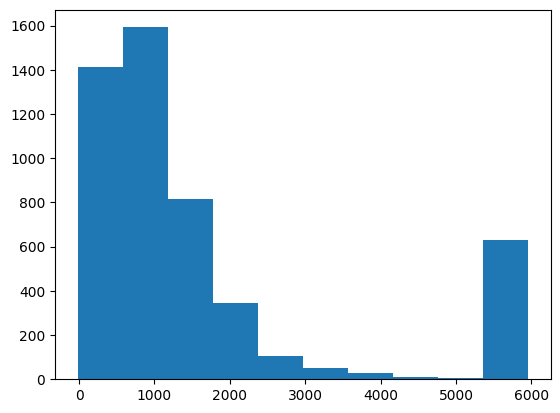

In [109]:
aveScore = 0
wins = 0
scores = []
for k in range(loops):
    #rev = [cards]
    rev = []
    deck52 = GenerateDeck()
    nrev = copy.deepcopy(deck52)
    #card = [#, color, suit]
    #                           -> [number (t=10, j=11, q=12, k=13), color (1=black, 2=red), suit (1=spade, 2=heart, 3=club, 4=diamond))] 0=unknown / -1=empty
    #tab = [[[cards], # of cards beneath (0-6)]]
    tab = [[],[],[],[],[],[],[]]
    tableau = [[],[],[],[],[],[],[]]
    for i in range(7):
        tab[i] = [],i
        for j in range(i):
            tableau[i].append(NewCard())

    #deck = [cards]
    deck = []

    #board [[Spades],[Hearts],[Clubs],[Diamonds]]
    board = [[],[],[],[]]

    for i in range(7):
        tab[i] = [[Reveal(NewCard())], tab[i][1]]

    for i in range(8):
        deck.append(0)
        deck.append(0)
        deck.append(0)
        deck[3*i+2] = Reveal(NewCard())
        deck[3*i+1] = NewCard()
        deck[3*i] = NewCard()

    deckLoc = 0
    score = 0

    lastShift = False
    s,t = QuickGame()
    scores.append(s)
    if (s > 5000):
        wins += 1
    aveScore += s/loops
print(f'Average Score {(int)(aveScore)} -> Win rate: {(int)(wins/loops*100)}%')
plt.hist(scores)

Useful function below for replaying the same deck over and over

In [92]:
def ResetBoard():
    global score; score = 0
    global deck; deck = copy.deepcopy(initDeck)
    global tab; tab = copy.deepcopy(initTab)
    global nrev; nrev = copy.deepcopy(initNRev)
    global rev; rev = copy.deepcopy(initRev)
    global board; board = [[],[],[],[]]